<a href="https://colab.research.google.com/github/Bismalaljan/colab-notebooks/blob/main/Another_copy_of_Titanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Import tools and load the data

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the Titanic dataset.. it's built right into seaborn!
df = sns.load_dataset("titanic")

print("Data loaded! Shape:", df.shape)

Data loaded! Shape: (891, 15)


# 2. Look at the first few rows

In [ ]:
# .head() shows us the first 5 rows by default
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


# 3. Understand your columns with .info()


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


# 4. Quick Summary Stats

In [ ]:
# .describe() gives stats for all numerical columns
df.describe().round(2)

,survived,pclass,age,sibsp,parch,fare
count,891.00,891.00,714.00,891.00,891.00,891.00
mean,0.38,2.31,29.70,0.52,0.38,32.20
std,0.49,0.84,14.53,1.10,0.81,49.69
min,0.00,1.00,0.42,0.00,0.00,0.00
25%,0.00,2.00,20.12,0.00,0.00,7.91
50%,0.00,3.00,28.00,0.00,0.00,14.45
75%,1.00,3.00,38.00,1.00,0.00,31.00
max,1.00,3.00,80.00,8.00,6.00,512.33


The mean of survived is 0.38... that means 38% of passengers survived overall. The mean fare is £32.20 but the max is £512! someone paid 16x the average! That std of 49.69 tells you fares were wildly spread out (remember Last lab?).

# 5. Who Survived? Splitting by Groups
An overall survival rate of 38% doesn't tell us much. The interesting question is: did survival depend on who you were? Let's find out using groupby().

In [ ]:
# groupby("sex") splits data into male group and female group
# ["survived"] picks just that column
# .mean() calculates the average survival (0 or 1) = the proportion who survived

survival_by_sex = df.groupby("sex")["survived"].mean().round(3)

print("Survival rate by gender:")
print(survival_by_sex)

Survival rate by gender:
sex
female    0.742
male      0.189
Name: survived, dtype: float64


# STOP AND THINK?

**74.2% of women** survived. Only **18.9% of men** did. That's not a small difference...it's nearly 4x higher. 😰

Can you please think **WHY?**

# YOUR LAB TASK 1
You need to find out, group the passengers by pclass and see if being in a more expensive cabin helped your **survival**?

In [ ]:
# Grouping by pclass to see the mean survival rate
survival_by_class = df.groupby("pclass")["survived"].mean().round(3)

print("Survival rate by Passenger Class:")
print(survival_by_class)

Survival rate by Passenger Class:
pclass
1    0.630
2    0.473
3    0.242
Name: survived, dtype: float64


# 6. Visualize Survival By Gender

A count plot shows us how many passengers fell into each category. We'll use **hue** to color bars by whether they survived.

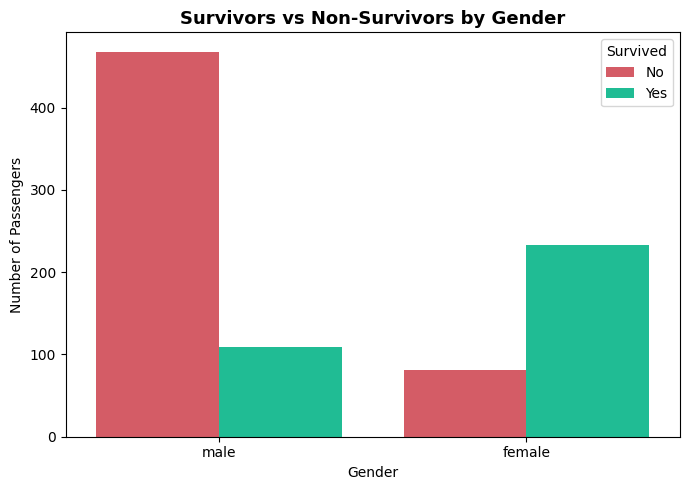

In [ ]:
# sns.countplot counts how many rows match each category
# hue="survived" colors each bar by survived (0) or not (1)

fig, ax = plt.subplots(figsize=(7, 5))

sns.countplot(
    data=df,
    x="sex",
    hue="survived",
    palette={0: "#e84855", 1: "#06d6a0"},  # 0=red, 1=green
    ax=ax
)

# Give it a clear title and labels
ax.set_title("Survivors vs Non-Survivors by Gender", fontsize=13, fontweight="bold")
ax.set_xlabel("Gender")
ax.set_ylabel("Number of Passengers")

# Rename the legend so it's human-readable
ax.legend(title="Survived", labels=["No", "Yes"])

plt.tight_layout()
plt.show()

# Lab task 2

Time for you to visualize survival by pclass. You can take AI's help but the code needs to be error free and accurate.

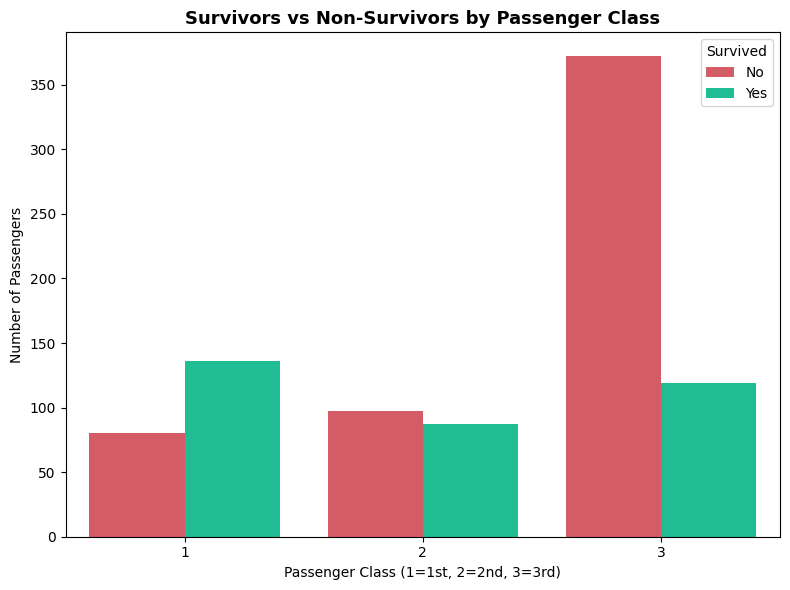

In [ ]:

# Set the figure size
fig, ax = plt.subplots(figsize=(8, 6))

# Create the countplot
sns.countplot(
    data=df,
    x="pclass",
    hue="survived",
    palette={0: "#e84855", 1: "#06d6a0"}, # Red for died, Green for survived
    ax=ax
)

# Add titles and clear labels
ax.set_title("Survivors vs Non-Survivors by Passenger Class", fontsize=13, fontweight="bold")
ax.set_xlabel("Passenger Class (1=1st, 2=2nd, 3=3rd)")
ax.set_ylabel("Number of Passengers")

# Fix the legend
ax.legend(title="Survived", labels=["No", "Yes"])

plt.tight_layout()
plt.show()

The summary of  this Titanic analysis is that people are saved by social and money trend as socially women and children are priorities they be take out first then men and first cabin people can easily come out other then 3rd cabin  people mostly saved in first cabin women and children are saved and 3rd cabin men were danger